# 03 - Classifier training
Predicts the service **group** (and from it the **trade**) from a customer's description.

Inputs: `phrasings_v2.csv` (columns `trade, group, text, split`). Splits: `train`, `test`, `test2` (a second, fresh test set), `oos_test` (out-of-scope sentences, used only for the 'unknown' fallback).

Install once if needed: `pip install scikit-learn pandas matplotlib seaborn joblib sentence-transformers`

In [1]:
import pandas as pd, numpy as np, joblib, warnings
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict, StratifiedKFold
warnings.filterwarnings('ignore')

d = pd.read_csv('phrasings_v2.csv')
train = d[d.split == 'train'].reset_index(drop=True)
test  = d[d.split == 'test'].reset_index(drop=True)
test2 = d[d.split == 'test2'].reset_index(drop=True)   # fresh test set, written after the extra training phrasings
oos   = d[d.split == 'oos_test'].reset_index(drop=True)
group_to_trade = d[d.split != 'oos_test'].drop_duplicates('group').set_index('group')['trade'].to_dict()
C_VALUE = 200   # logistic regression strength; larger = sharper confidences
print(len(train), 'train |', len(test), 'test |', len(test2), 'test2 |', len(oos), 'out-of-scope')
print(train.groupby('group').size().describe()[['min', 'max']])

474 train | 93 test | 62 test2 | 20 out-of-scope
min    14.0
max    16.0
dtype: float64


## 1. Baseline: character TF-IDF + logistic regression
Character n-grams cope better than words with Swahili word forms and spelling variation.

In [2]:
def evaluate(name, predict_fn, ts=None, label='test'):
    ts = test if ts is None else ts
    p = predict_fn(ts.text)
    acc = accuracy_score(ts.group, p)
    trade_acc = np.mean([group_to_trade[x] == t for x, t in zip(p, ts.trade)])
    f1 = f1_score(ts.group, p, average='macro')
    print(f'{name:22s} [{label}] group acc {acc:.3f} | trade acc {trade_acc:.3f} | macro-F1 {f1:.3f}')
    return p

tfidf = make_pipeline(
    TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), sublinear_tf=True),
    LogisticRegression(max_iter=3000, C=C_VALUE))
tfidf.fit(train.text, train.group)
p_tfidf = evaluate('TF-IDF + LogReg', tfidf.predict)
evaluate('TF-IDF + LogReg', tfidf.predict, test2, 'test2')

TF-IDF + LogReg        [test] group acc 0.774 | trade acc 0.849 | macro-F1 0.781
TF-IDF + LogReg        [test2] group acc 0.694 | trade acc 0.919 | macro-F1 0.702


array(['ac_cooling_coil', 'ac_cooling_coil', 'ac_deep_clean',
       'ac_deep_clean', 'ac_gas_compressor', 'mcb_fuse_breaker',
       'ac_gas_compressor', 'ac_fan_blower', 'ac_install_uninstall',
       'ac_electrical_pcb', 'ac_cooling_coil', 'ac_grill_misc',
       'ac_install_uninstall', 'ac_gas_compressor', 'ac_water_leakage',
       'ac_gas_compressor', 'microwave_controls', 'microwave_controls',
       'microwave_fan_light_misc', 'microwave_door',
       'microwave_not_heating', 'microwave_fan_light_misc',
       'geyser_heater', 'microwave_not_heating', 'microwave_not_heating',
       'microwave_turntable', 'tv_home_theater_install', 'doorbell',
       'fan_repair_install', 'lights_bulbs', 'wash_basin',
       'geyser_heater', 'inverter_battery', 'inverter_battery',
       'lights_bulbs', 'lights_bulbs', 'switch_socket_board',
       'mcb_fuse_breaker', 'switch_socket_board', 'switch_socket_board',
       'ac_install_uninstall', 'tv_home_theater_install', 'wiring',
       'wiring

## 2. Sentence embeddings + logistic regression
A multilingual embedding model maps sentences with similar meaning close together, even in different words or languages, so 'kiyoyozi kinamwaga maji' can land near 'AC is leaking water'.

`MODEL_NAME` is the one thing to change. `intfloat/multilingual-e5-small` is a small XLM-R based model that lists Swahili among its languages. `sentence-transformers/LaBSE` is larger and also covers Swahili. First run downloads the model (several hundred MB). If it fails the notebook carries on with the baseline.

In [3]:
MODEL_NAME = 'intfloat/multilingual-e5-small'
PREFIX = 'query: '          # e5 models expect a prefix; set to '' for LaBSE

emb_clf = None
try:
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer(MODEL_NAME)
    def embed(texts):
        return encoder.encode([PREFIX + t for t in texts], normalize_embeddings=True, show_progress_bar=False)
    X_train = embed(train.text)
    emb_clf = LogisticRegression(max_iter=3000, C=C_VALUE).fit(X_train, train.group)
    p_emb = evaluate('Embeddings + LogReg', lambda s: emb_clf.predict(embed(s)))
    evaluate('Embeddings + LogReg', lambda s: emb_clf.predict(embed(s)), test2, 'test2')
except Exception as e:
    print('Embedding model not available:', type(e).__name__, '-', str(e)[:200])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3622.21it/s]


Embeddings + LogReg    [test] group acc 0.817 | trade acc 0.914 | macro-F1 0.814
Embeddings + LogReg    [test2] group acc 0.790 | trade acc 0.903 | macro-F1 0.787


## 3. Pick the better model and look at the mistakes

In [4]:
if emb_clf is not None and accuracy_score(test.group, p_emb) > accuracy_score(test.group, p_tfidf):
    BEST = 'embeddings'
    proba = lambda s: emb_clf.predict_proba(embed(s)); classes = emb_clf.classes_
else:
    BEST = 'tfidf'
    proba = lambda s: tfidf.predict_proba(s); classes = tfidf.classes_
print('Using:', BEST)

pred = classes[proba(test.text).argmax(1)]
print(classification_report(test.group, pred, zero_division=0))
for t, g, q in zip(test.text, test.group, pred):
    if g != q: print(f'{t!r}\n    true={g}  pred={q}')

Using: embeddings
                          precision    recall  f1-score   support

         ac_cooling_coil       1.00      1.00      1.00         3
           ac_deep_clean       0.50      1.00      0.67         3
       ac_electrical_pcb       1.00      1.00      1.00         3
           ac_fan_blower       0.75      1.00      0.86         3
       ac_gas_compressor       1.00      0.67      0.80         3
           ac_grill_misc       1.00      0.67      0.80         3
    ac_install_uninstall       0.50      0.67      0.57         3
        ac_water_leakage       1.00      0.33      0.50         3
                doorbell       1.00      1.00      1.00         3
          drain_blockage       0.67      0.67      0.67         3
      fan_repair_install       0.50      0.67      0.57         3
           geyser_heater       0.75      1.00      0.86         3
        inverter_battery       1.00      0.67      0.80         3
            lights_bulbs       0.75      1.00      0.86  

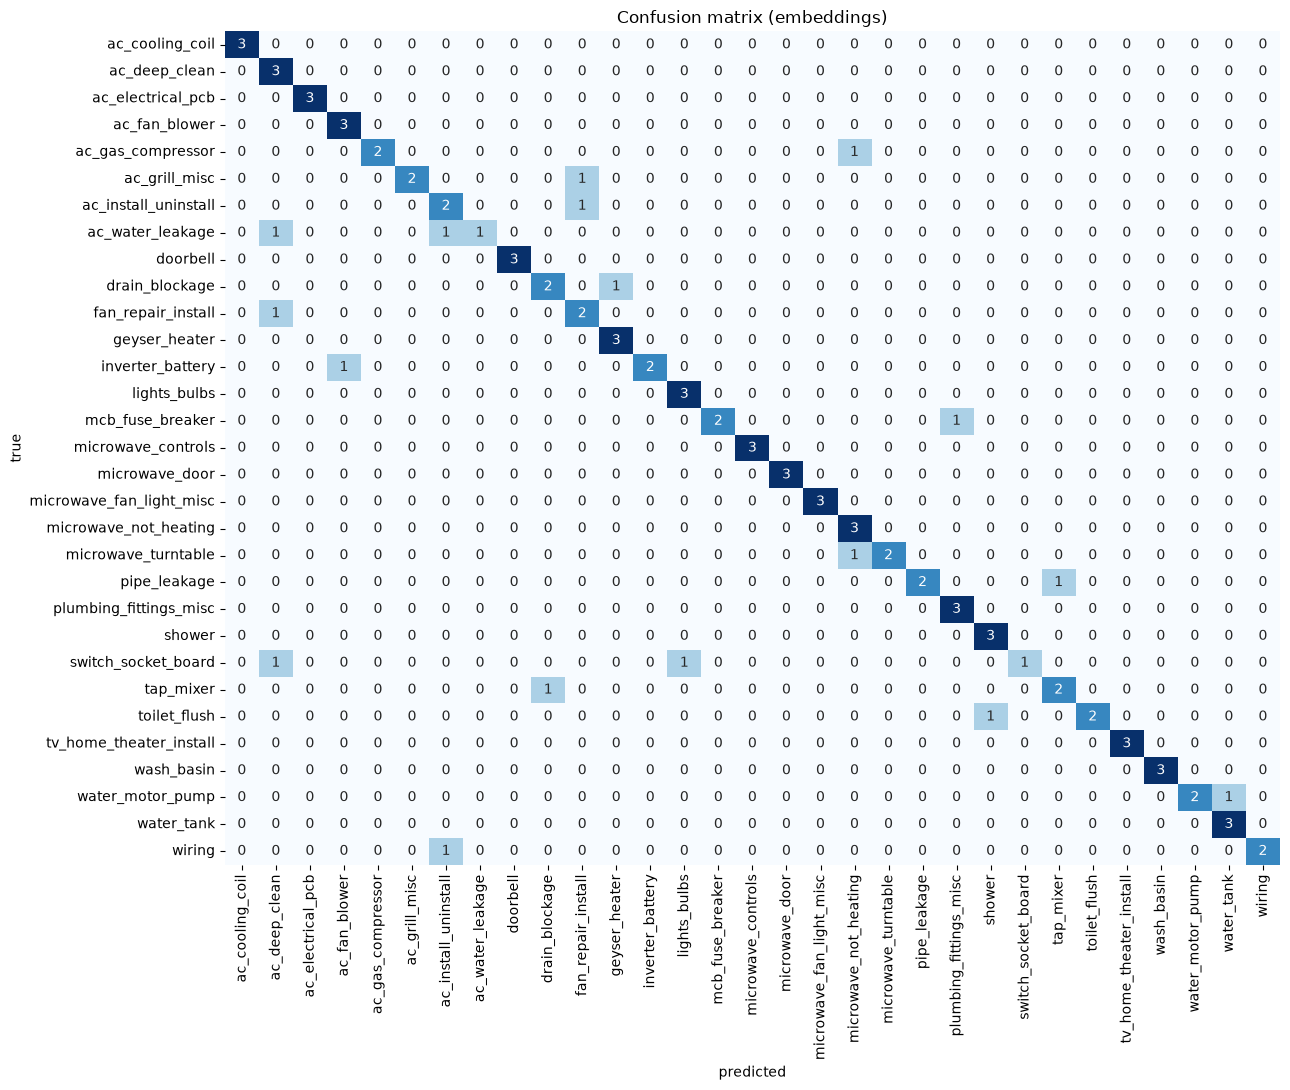

In [5]:
cm = confusion_matrix(test.group, pred, labels=classes)
plt.figure(figsize=(13, 11))
sns.heatmap(cm, xticklabels=classes, yticklabels=classes, cmap='Blues', cbar=False, annot=True, fmt='d')
plt.xlabel('predicted'); plt.ylabel('true'); plt.title(f'Confusion matrix ({BEST})')
plt.tight_layout(); plt.show()

## 4. The 'unknown' fallback
If the top probability is below a threshold the app shows the three trade tiles instead of guessing. The threshold is chosen on **cross-validated predictions from the training set plus half of the out-of-scope sentences**, then checked on the **test set plus the other half**, so the test numbers are not used to pick it.

In [6]:
# out-of-fold in-scope confidences from training data only
if BEST == 'embeddings':
    X_all = embed(train.text); base = LogisticRegression(max_iter=3000, C=C_VALUE)
    oof = cross_val_predict(base, X_all, train.group, cv=StratifiedKFold(3, shuffle=True, random_state=0), method='predict_proba')
else:
    base = make_pipeline(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), sublinear_tf=True), LogisticRegression(max_iter=3000, C=C_VALUE))
    oof = cross_val_predict(base, train.text, train.group, cv=StratifiedKFold(3, shuffle=True, random_state=0), method='predict_proba')
oof_conf = oof.max(1)
oof_correct = (np.array(sorted(train.group.unique()))[oof.argmax(1)] == train.group.values)

oos_tune, oos_eval = oos.iloc[::2], oos.iloc[1::2]
conf_oos_tune = proba(oos_tune.text).max(1)

rows = []
for th in np.arange(0.05, 0.80, 0.05):
    kept = oof_conf >= th
    rows.append({'threshold': round(th, 2),
                 'in-scope kept': kept.mean(),
                 'accuracy when kept': oof_correct[kept].mean() if kept.any() else np.nan,
                 'out-of-scope rejected': (conf_oos_tune < th).mean()})
sweep = pd.DataFrame(rows); print(sweep.round(2).to_string(index=False))

 threshold  in-scope kept  accuracy when kept  out-of-scope rejected
      0.05           1.00                0.87                    0.0
      0.10           1.00                0.87                    0.0
      0.15           0.99                0.88                    0.5
      0.20           0.97                0.88                    0.6
      0.25           0.93                0.89                    0.9
      0.30           0.87                0.91                    1.0
      0.35           0.82                0.93                    1.0
      0.40           0.77                0.95                    1.0
      0.45           0.72                0.96                    1.0
      0.50           0.66                0.98                    1.0
      0.55           0.62                0.99                    1.0
      0.60           0.56                0.99                    1.0
      0.65           0.49                0.99                    1.0
      0.70           0.42         

In [7]:
# choose the largest threshold that still keeps at least 80% of in-scope phrasings
THRESHOLD = float(sweep[sweep['in-scope kept'] >= 0.80]['threshold'].max())
print('THRESHOLD =', THRESHOLD)

conf_test = proba(test.text).max(1); conf_oos_eval = proba(oos_eval.text).max(1)
kept = conf_test >= THRESHOLD
print(f'test: kept {kept.mean():.2f} of in-scope, accuracy on kept {np.mean(pred[kept] == test.group.values[kept]):.3f}')
print(f'held-out out-of-scope rejected: {(conf_oos_eval < THRESHOLD).mean():.2f}  ({len(oos_eval)} sentences)')

THRESHOLD = 0.35
test: kept 0.80 of in-scope, accuracy on kept 0.892
held-out out-of-scope rejected: 0.80  (10 sentences)


## 5. Save the model and define the app-facing function
The mobile team only needs `diagnose(text)`. It returns the trade, group and confidence, or `unknown` when confidence is below the threshold.

In [8]:
# refit the chosen model on train only (test stays unseen); for the final build you could add test phrasings back in
bundle = {'best': BEST, 'threshold': THRESHOLD, 'group_to_trade': group_to_trade}
if BEST == 'embeddings':
    bundle.update(model_name=MODEL_NAME, prefix=PREFIX, clf=emb_clf)
else:
    bundle.update(clf=tfidf)
joblib.dump(bundle, 'classifier.joblib')

def diagnose(text):
    pr = proba([text])[0]
    i = pr.argmax(); conf = float(pr[i]); grp = classes[i]
    if conf < THRESHOLD:
        return {'status': 'unknown', 'confidence': round(conf, 2)}
    return {'status': 'ok', 'trade': group_to_trade[grp], 'group': grp, 'confidence': round(conf, 2)}

for q in ['bomba la jikoni linavuja', 'my AC is not cooling', 'stima imekatika sebuleni', 'I need a painter']:
    print(q, '->', diagnose(q))

bomba la jikoni linavuja -> {'status': 'ok', 'trade': 'plumber', 'group': 'tap_mixer', 'confidence': 0.74}
my AC is not cooling -> {'status': 'ok', 'trade': 'appliance', 'group': 'ac_electrical_pcb', 'confidence': 0.41}
stima imekatika sebuleni -> {'status': 'unknown', 'confidence': 0.17}
I need a painter -> {'status': 'unknown', 'confidence': 0.18}
